# Detección de anomalías en transacciones financieras

**Proyecto:** Implementación y evaluación de un sistema de detección de anomalías con aprendizaje automático en flujos de datos financieros.


**Dataset:** sintético, generado en este cuaderno con NumPy y Faker: 185 mil transacciones en USD de 3.000 clientes de 11 ciudades del Ecuador, con códigos de comercio (MCC), canales digitales (App, Banca web, SPI, POS, ATM) y episodios de fraude inyectados.

**Modelos:** Isolation Forest · Local Outlier Factor · Autoencoder denso · One-Class SVM · HistGradientBoosting (referencia supervisada).

# FASE 1 · Preparación del entorno y exploración de datos

## Paso 1. Importar librerías y fijar semilla

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, roc_curve,
                             confusion_matrix)

warnings.filterwarnings('ignore')
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)

DATA = Path('../data'); FIG = Path('../figuras'); RES = Path('../resultados')
for p in (DATA, FIG, RES): p.mkdir(exist_ok=True)
import sklearn; print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.1.3


## Paso 2. Generar el dataset sintético de transacciones

In [2]:
# --- Catálogos del contexto ecuatoriano -------------------------------------------
# ciudad: (provincia, latitud, longitud, peso de clientes)
CIUDADES = {
 'Quito':('Pichincha',-0.1807,-78.4678,.28), 'Guayaquil':('Guayas',-2.1709,-79.9224,.30),
 'Cuenca':('Azuay',-2.9001,-79.0059,.10), 'Santo Domingo':('Santo Domingo de los Tsáchilas',-0.2530,-79.1754,.06),
 'Machala':('El Oro',-3.2581,-79.9554,.05), 'Manta':('Manabí',-0.9677,-80.7089,.05),
 'Ambato':('Tungurahua',-1.2491,-78.6168,.05), 'Loja':('Loja',-3.9931,-79.2042,.04),
 'Riobamba':('Chimborazo',-1.6636,-78.6546,.03), 'Ibarra':('Imbabura',0.3517,-78.1223,.02),
 'Esmeraldas':('Esmeraldas',0.9682,-79.6517,.02)}
# MCC: (descripción, monto base USD, dispersión, frecuencia)
MCC = {5411:('Supermercados',25,.7,.22), 5541:('Gasolineras',18,.5,.12), 5812:('Restaurantes',15,.6,.14),
       5912:('Farmacias',12,.6,.08), 4900:('Servicios básicos',35,.5,.08), 5311:('Grandes almacenes',45,.8,.07),
       4829:('Transferencias',80,1.0,.13), 6011:('Retiro cajero',40,.6,.10), 5732:('Electrónica',120,.9,.03),
       7995:('Apuestas en línea',20,.9,.03)}
cn = list(CIUDADES); cp = np.array([CIUDADES[c][3] for c in cn]); cp /= cp.sum()
mk = np.array(list(MCC)); mp = np.array([MCC[m][3] for m in mk]); mp /= mp.sum()

def canal_para(m):
    if m == 6011: return 'ATM'
    if m == 4829: return rng.choice(['App móvil','Banca web','Transferencia SPI'], p=[.55,.20,.25])
    if m in (5411,5541,5812,5912): return rng.choice(['POS','App móvil'], p=[.85,.15])
    if m == 4900: return rng.choice(['App móvil','Banca web','POS'], p=[.50,.35,.15])
    if m == 7995: return rng.choice(['App móvil','Banca web'], p=[.6,.4])
    return rng.choice(['POS','App móvil','Banca web'], p=[.5,.3,.2])

# --- Clientes ---------------------------------------------------------------------
NC = 3000
cli = pd.DataFrame({'id_cliente':[f'CL{i:05d}' for i in range(NC)],
    'ciudad_habitual':rng.choice(cn, NC, p=cp), 'edad_cliente':rng.integers(18,79,NC),
    'antiguedad_cuenta_meses':rng.integers(1,240,NC),
    'segmento':rng.choice(['Masivo','Preferente','Pymes'], NC, p=[.72,.18,.10]),
    'tipo_tarjeta':rng.choice(['Débito','Crédito'], NC, p=[.65,.35])})
cli['escala'] = cli.segmento.map({'Masivo':.8,'Preferente':1.8,'Pymes':2.5}) * rng.lognormal(0,.35,NC)
cli['saldo_promedio_usd'] = np.round(cli.escala * rng.lognormal(6.6,.8,NC), 2)
cli['actividad'] = rng.gamma(4,15,NC)              # transacciones esperadas al mes

# --- Transacciones normales (septiembre 2026) ------------------------------------------
INICIO = pd.Timestamp('2026-09-01')
p_hora = np.array([1,.5,.3,.3,.4,.8,2,4,6,7,7,7.5,8,7.5,7,7,7.5,8,8,7,6,4.5,3,2]); p_hora /= p_hora.sum()
filas = []
for c in cli.itertuples():
    n = rng.poisson(c.actividad)
    dias, hrs = rng.integers(0,30,n), rng.choice(24,n,p=p_hora)
    mins, segs = rng.integers(0,60,n), rng.integers(0,60,n)
    mccs, viaje = rng.choice(mk,n,p=mp), rng.random(n) < .06
    for k in range(n):
        m = mccs[k]; base, sig = MCC[m][1], MCC[m][2]
        monto = max(base * c.escala * rng.lognormal(0, sig), .5)
        ciudad = rng.choice(cn, p=cp) if viaje[k] else c.ciudad_habitual
        t = INICIO + pd.Timedelta(days=int(dias[k]), hours=int(hrs[k]), minutes=int(mins[k]), seconds=int(segs[k]))
        filas.append((c.id_cliente, t, round(monto,2), m, canal_para(m), ciudad,
                      int(rng.random()<.02), int(rng.poisson(.04)), rng.beta(2,9), 0))

# --- Episodios de fraude (ráfagas de 1 a 6 transacciones) -------------------------------
p_noche = np.r_[np.ones(6)*3, np.ones(18)*.5]; p_noche /= p_noche.sum()
for v in rng.choice(NC, 520, replace=False):
    c = cli.iloc[v]
    hora = rng.choice(24) if rng.random() < .45 else rng.choice(24, p=p_noche)
    t0 = INICIO + pd.Timedelta(days=int(rng.integers(0,30)), hours=int(hora), minutes=int(rng.integers(0,60)))
    k = int(rng.choice([1,2,3,4,5,6], p=[.30,.20,.18,.14,.10,.08]))
    camuflado = rng.random() < .18                      # fraudes que imitan al cliente
    for j in range(k):
        t = t0 + pd.Timedelta(minutes=int(rng.integers(1,25))*j)
        if camuflado:
            m = rng.choice(mk, p=mp); monto = MCC[m][1]*c.escala*rng.lognormal(.3,.7)
            filas.append((c.id_cliente, t, round(monto,2), m, canal_para(m), c.ciudad_habitual,
                          int(rng.random()<.15), int(rng.poisson(.15)), rng.beta(2.5,7), 1)); continue
        m = rng.choice([5732,7995,4829,6011,5311,5812], p=[.25,.15,.30,.15,.10,.05])
        monto = rng.uniform(1,6) if rng.random() < .22 else MCC[m][1]*c.escala*rng.lognormal(1.4,.7)  # prueba de tarjeta vs. vaciado
        ciudad = rng.choice(cn, p=cp) if rng.random() < .55 else c.ciudad_habitual
        filas.append((c.id_cliente, t, round(monto,2), m, canal_para(m), ciudad,
                      int(rng.random()<.65), int(rng.poisson(.9)), rng.beta(5,4), 1))

df = pd.DataFrame(filas, columns=['id_cliente','fecha_hora','monto_usd','mcc','canal','ciudad_transaccion',
     'dispositivo_nuevo','intentos_fallidos_pin','score_ip_riesgo','es_fraude'])
df = df.merge(cli.drop(columns=['escala','actividad']), on='id_cliente')
print('Transacciones generadas:', len(df))

Transacciones generadas: 185484


**Explicación del código:**
- Se definen catálogos locales: 11 ciudades con su provincia y coordenadas, y 10 códigos de comercio MCC usados en Ecuador (supermercados, gasolineras, SPI/transferencias, cajeros, apuestas, etc.) con un monto típico en USD.
- Se crean 3.000 clientes con segmento (Masivo, Preferente, Pymes), edad, antigüedad, tipo de tarjeta y saldo promedio.
- Cada cliente genera transacciones normales durante septiembre 2026, con más actividad de día y montos que dependen del MCC y del segmento. Un 6 % ocurre fuera de su ciudad (viajes legítimos).
- Se inyectan 520 episodios de fraude en ráfagas: predominan la madrugada, dispositivos nuevos, intentos fallidos de PIN, MCC de riesgo y montos muy altos o micro-montos de "prueba de tarjeta". El 18 % son fraudes camuflados que imitan al cliente, para que el problema no sea trivial.

## Paso 2 (b). Nombres de clientes y comercios con Faker

In [3]:
try:
    from faker import Faker
except ImportError:                                   # en Colab se instala automáticamente
    import sys, subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'faker'])
    from faker import Faker

fake = Faker('es_ES'); Faker.seed(SEED)              # semilla propia: no altera el generador de NumPy
# Identidades sintéticas de los 3.000 clientes
nombres_clientes = {c: fake.name() for c in cli.id_cliente}
# Catálogo de 15 comercios ficticios por código MCC
comercios = {m: [fake.company() for _ in range(15)] for m in MCC}
df['nombre_cliente'] = df.id_cliente.map(nombres_clientes)
df['nombre_comercio'] = [fake.random_element(comercios[m]) for m in df.mcc]
print('Ejemplos de clientes :', list(nombres_clientes.values())[:3])
print('Ejemplos de comercios:', {MCC[m][0]: comercios[m][0] for m in list(MCC)[:4]})

Ejemplos de clientes : ['Albano Llopis Hierro', 'Buenaventura de Bonet', 'Ileana Antón-Andrés']
Ejemplos de comercios: {'Supermercados': 'Almansa & Asociados S.L.N.E', 'Gasolineras': 'Inversiones Farré & Asociados S.Coop.', 'Restaurantes': 'Caridad Español Peña S.L.', 'Farmacias': 'Fábrica Españolas S.Coop.'}


**Explicación del código:**
- Se usa la librería **Faker** (configuración regional en español) para dar a cada cliente un nombre ficticio y crear un catálogo de 15 comercios ficticios por cada código MCC; cada transacción recibe uno de esos comercios.
- Faker tiene su propia semilla, así que no modifica la secuencia aleatoria de NumPy: los montos, fechas y fraudes generados en el paso anterior quedan iguales.
- Estas columnas dan realismo al dataset, pero **no entran a los modelos**: un nombre propio no debe influir en la decisión de fraude (principio de minimización de la LOPDP).

## Paso 3. Variables derivadas de comportamiento y valores faltantes

In [4]:
def haversine(a1, o1, a2, o2):
    a1, o1, a2, o2 = map(np.radians, [a1, o1, a2, o2])
    d = np.sin((a2-a1)/2)**2 + np.cos(a1)*np.cos(a2)*np.sin((o2-o1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(d))

lat = {k:v[1] for k,v in CIUDADES.items()}; lon = {k:v[2] for k,v in CIUDADES.items()}
df['provincia'] = df.ciudad_transaccion.map({k:v[0] for k,v in CIUDADES.items()})
df['descripcion_mcc'] = df.mcc.map({k:v[0] for k,v in MCC.items()})
df['distancia_ciudad_habitual_km'] = haversine(df.ciudad_habitual.map(lat), df.ciudad_habitual.map(lon),
                                               df.ciudad_transaccion.map(lat), df.ciudad_transaccion.map(lon)).round(1)

df = df.sort_values(['id_cliente','fecha_hora']).reset_index(drop=True)
g = df.groupby('id_cliente')
df['tx_ultimas_24h'] = g.rolling('24h', on='fecha_hora')['monto_usd'].count().values - 1
df['minutos_desde_ultima_tx'] = g.fecha_hora.diff().dt.total_seconds().div(60).round(1)
df['monto_promedio_cliente'] = g.monto_usd.transform(lambda s: s.shift().expanding().mean()).round(2)
df['ratio_monto_vs_promedio'] = (df.monto_usd / df.monto_promedio_cliente).round(3)

# Faltantes: el score de IP no existe en POS/ATM (estructural) + pérdidas aleatorias
df.loc[df.canal.isin(['POS','ATM']), 'score_ip_riesgo'] = np.nan
df.loc[rng.random(len(df)) < .02, 'score_ip_riesgo'] = np.nan
df.loc[rng.random(len(df)) < .035, 'saldo_promedio_usd'] = np.nan
df['score_ip_riesgo'] = df.score_ip_riesgo.round(3)

df = df.sort_values('fecha_hora').reset_index(drop=True)
df.insert(0, 'id_transaccion', [f'TX{i:07d}' for i in range(len(df))])
df.to_csv(DATA/'transacciones_ecuador_sinteticas.csv', index=False)
print('Dataset guardado en data/transacciones_ecuador_sinteticas.csv ->', df.shape)

Dataset guardado en data/transacciones_ecuador_sinteticas.csv -> (185484, 26)


**Explicación del código:**
- `haversine` calcula la distancia en km entre la ciudad habitual del cliente y la ciudad donde se hizo la transacción.
- Por cliente y en orden cronológico se calculan: número de transacciones en las últimas 24 h (detecta ráfagas), minutos desde la transacción anterior, monto promedio histórico y la razón entre el monto actual y ese promedio. Solo se usa información del pasado, como ocurriría en tiempo real.
- Se introducen valores faltantes realistas: el `score_ip_riesgo` no existe en POS y ATM porque no hay dirección IP, y además hay pérdidas aleatorias en el saldo.
- El dataset final se guarda como CSV en la carpeta `data`.

## Paso 4. Vista general del dataset

In [5]:
print('Filas:', df.shape[0], '| Columnas:', df.shape[1])
print('Periodo:', df.fecha_hora.min(), '->', df.fecha_hora.max())
print('Clientes:', df.id_cliente.nunique(), '| Ciudades:', df.ciudad_transaccion.nunique())
display(df.head(5))
display(df.dtypes.astype(str).to_frame('tipo'))

Filas: 185484 | Columnas: 26
Periodo: 2026-09-01 00:00:20 -> 2026-09-30 23:59:46
Clientes: 3000 | Ciudades: 11


,id_transaccion,id_cliente,fecha_hora,monto_usd,mcc,canal,ciudad_transaccion,dispositivo_nuevo,intentos_fallidos_pin,score_ip_riesgo,es_fraude,ciudad_habitual,edad_cliente,antiguedad_cuenta_meses,segmento,tipo_tarjeta,saldo_promedio_usd,nombre_cliente,nombre_comercio,provincia,descripcion_mcc,distancia_ciudad_habitual_km,tx_ultimas_24h,minutos_desde_ultima_tx,monto_promedio_cliente,ratio_monto_vs_promedio
0,TX0000000,CL00622,2026-09-01 00:00:20,3.74,5541,POS,Esmeraldas,0,0,NaN,0,Esmeraldas,67,50,Masivo,Crédito,266.31,Leocadia de Ocaña,Inversiones Inteligentes S.A.,Esmeraldas,Gasolineras,0.0,0.0,NaN,NaN,NaN
1,TX0000001,CL00979,2026-09-01 00:00:31,5.46,5812,POS,Quito,0,0,NaN,0,Quito,48,25,Masivo,Débito,350.36,Sandra Simó Vazquez,Báez y Chacón S.Coop.,Pichincha,Restaurantes,0.0,0.0,NaN,NaN,NaN
2,TX0000002,CL00114,2026-09-01 00:00:48,93.05,4829,App móvil,Quito,0,0,0.152,0,Quito,30,124,Masivo,Débito,NaN,Irene Becerra Murillo,Industrias Zurita y asociados S.Com.,Pichincha,Transferencias,0.0,0.0,NaN,NaN,NaN
3,TX0000003,CL02403,2026-09-01 00:00:57,39.44,5812,App móvil,Loja,0,0,0.532,0,Loja,67,24,Preferente,Débito,1797.78,Jonatan Lorenzo Cuéllar,Castejón y asociados S.A.,Loja,Restaurantes,0.0,0.0,NaN,NaN,NaN
4,TX0000004,CL01428,2026-09-01 00:01:16,25.32,5541,POS,Machala,0,1,NaN,0,Machala,72,77,Masivo,Débito,1762.51,Jose Francisco Bustos Mas,Inversiones Inteligentes S.A.,El Oro,Gasolineras,0.0,0.0,NaN,NaN,NaN


,tipo
id_transaccion,object
id_cliente,object
fecha_hora,datetime64[ns]
monto_usd,float64
mcc,int64
canal,object
ciudad_transaccion,object
dispositivo_nuevo,int64
intentos_fallidos_pin,int64
score_ip_riesgo,float64


**Explicación del código:** muestra el tamaño del dataset, el rango de fechas, el número de clientes y ciudades, las primeras filas y el tipo de dato de cada columna (numérica, categórica o fecha).

## Paso 5. Distribución de clases (normal vs. fraude)

,transacciones,porcentaje
es_fraude,,
Normal,184110,99.259
Fraude,1374,0.741


Razón de desbalance ≈ 1 : 134


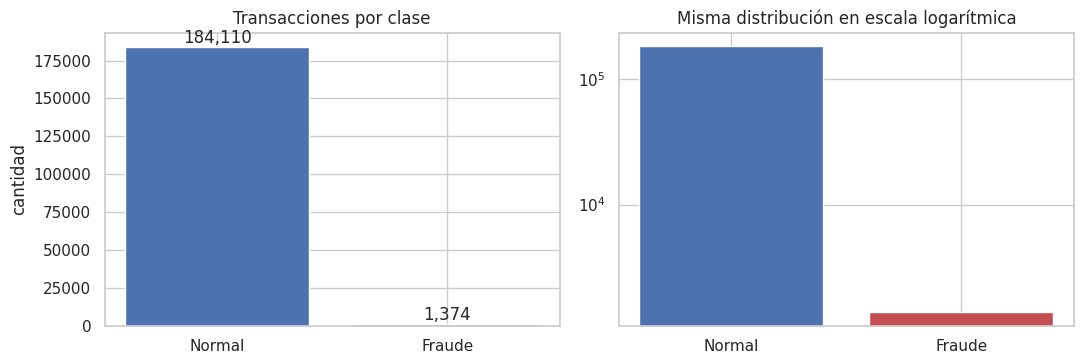

In [6]:
conteo = df.es_fraude.value_counts().rename({0:'Normal',1:'Fraude'})
tabla = pd.DataFrame({'transacciones':conteo, 'porcentaje':(conteo/len(df)*100).round(3)})
display(tabla)
print(f'Razón de desbalance ≈ 1 : {conteo.Normal/conteo.Fraude:.0f}')

fig, ax = plt.subplots(1, 2, figsize=(11,3.8))
ax[0].bar(conteo.index, conteo.values, color=['#4C72B0','#C44E52'])
ax[0].set_title('Transacciones por clase'); ax[0].set_ylabel('cantidad')
for i,v in enumerate(conteo.values): ax[0].text(i, v, f'{v:,}', ha='center', va='bottom')
ax[1].bar(conteo.index, conteo.values, color=['#4C72B0','#C44E52']); ax[1].set_yscale('log')
ax[1].set_title('Misma distribución en escala logarítmica')
plt.tight_layout(); plt.savefig(FIG/'01_distribucion_clases.png', dpi=150); plt.show()

**Explicación del código:** cuenta cuántas transacciones son normales y cuántas fraudulentas, calcula su porcentaje y la razón de desbalance, y lo grafica en escala normal y logarítmica (en escala normal la barra de fraude casi no se ve).

## Paso 6. Estadísticos descriptivos por variable

In [7]:
num_cols = ['monto_usd','saldo_promedio_usd','edad_cliente','antiguedad_cuenta_meses','distancia_ciudad_habitual_km',
            'tx_ultimas_24h','minutos_desde_ultima_tx','ratio_monto_vs_promedio','intentos_fallidos_pin',
            'dispositivo_nuevo','score_ip_riesgo']
desc = df[num_cols].describe().T.round(2)
display(desc)
print('Media por clase (variables clave):')
display(df.groupby('es_fraude')[['monto_usd','ratio_monto_vs_promedio','tx_ultimas_24h','dispositivo_nuevo',
                                 'intentos_fallidos_pin','score_ip_riesgo','distancia_ciudad_habitual_km']].mean().round(2)
        .rename(index={0:'Normal',1:'Fraude'}))
desc.to_csv(RES/'estadisticos_descriptivos.csv')

,count,mean,std,min,25%,50%,75%,max
monto_usd,185484.0,61.45,144.79,0.51,13.94,27.31,58.32,11801.21
saldo_promedio_usd,178934.0,1228.39,1488.35,22.58,403.41,762.21,1456.44,18505.14
edad_cliente,185484.0,47.57,17.55,18.00,33.00,48.00,63.00,78.00
antiguedad_cuenta_meses,185484.0,119.71,67.82,1.00,61.00,120.00,177.00,239.00
distancia_ciudad_habitual_km,185484.0,11.60,54.99,0.00,0.00,0.00,0.00,553.90
tx_ultimas_24h,185484.0,2.53,1.96,0.00,1.00,2.00,4.00,16.00
minutos_desde_ultima_tx,182484.0,677.05,881.55,0.00,119.80,350.45,975.40,19412.90
ratio_monto_vs_promedio,182484.0,1.18,2.59,0.00,0.31,0.57,1.14,314.38
intentos_fallidos_pin,185484.0,0.05,0.22,0.00,0.00,0.00,0.00,6.00
dispositivo_nuevo,185484.0,0.02,0.15,0.00,0.00,0.00,0.00,1.00


Media por clase (variables clave):


,monto_usd,ratio_monto_vs_promedio,tx_ultimas_24h,dispositivo_nuevo,intentos_fallidos_pin,score_ip_riesgo,distancia_ciudad_habitual_km
es_fraude,,,,,,,
Normal,59.49,1.15,2.53,0.02,0.04,0.18,11.0
Fraude,324.03,5.38,3.14,0.56,0.78,0.52,92.2


**Explicación del código:** calcula media, desviación estándar, mínimo, cuartiles y máximo de cada variable numérica, y compara las medias entre transacciones normales y fraudulentas para ver qué variables separan mejor las clases.

## Paso 7. Análisis de valores faltantes

,% faltante
score_ip_riesgo,64.37
saldo_promedio_usd,3.53
minutos_desde_ultima_tx,1.62
monto_promedio_cliente,1.62
ratio_monto_vs_promedio,1.62


Faltantes de score_ip_riesgo por canal (%):


,% faltante
canal,
ATM,100.0
App móvil,1.9
Banca web,1.7
POS,100.0
Transferencia SPI,2.0


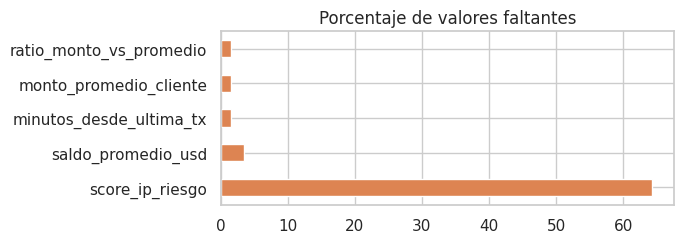

In [8]:
falt = (df.isna().mean()*100).round(2)
falt = falt[falt > 0].sort_values(ascending=False).to_frame('% faltante')
display(falt)
print('Faltantes de score_ip_riesgo por canal (%):')
display((df.groupby('canal').score_ip_riesgo.apply(lambda s: s.isna().mean()*100)).round(1).to_frame('% faltante'))
falt['% faltante'].plot.barh(figsize=(7,2.6), color='#DD8452', title='Porcentaje de valores faltantes')
plt.tight_layout(); plt.savefig(FIG/'02_faltantes.png', dpi=150); plt.show()

**Explicación del código:** calcula el porcentaje de valores vacíos por columna y revisa por canal el caso de `score_ip_riesgo`. Se confirma que en POS y ATM falta casi el 100 % (faltante estructural, no un error), mientras que en canales digitales solo falta un 2 %.

## Paso 8. Outliers estructurales (regla IQR)

,% outliers (IQR),% fraude dentro de los outliers
monto_usd,10.03,3.66
saldo_promedio_usd,7.97,0.69
edad_cliente,0.00,NaN
antiguedad_cuenta_meses,0.00,NaN
distancia_ciudad_habitual_km,4.97,5.84
tx_ultimas_24h,0.94,1.32
minutos_desde_ultima_tx,5.25,0.40
ratio_monto_vs_promedio,9.86,3.67
intentos_fallidos_pin,4.24,8.99
dispositivo_nuevo,2.33,17.71


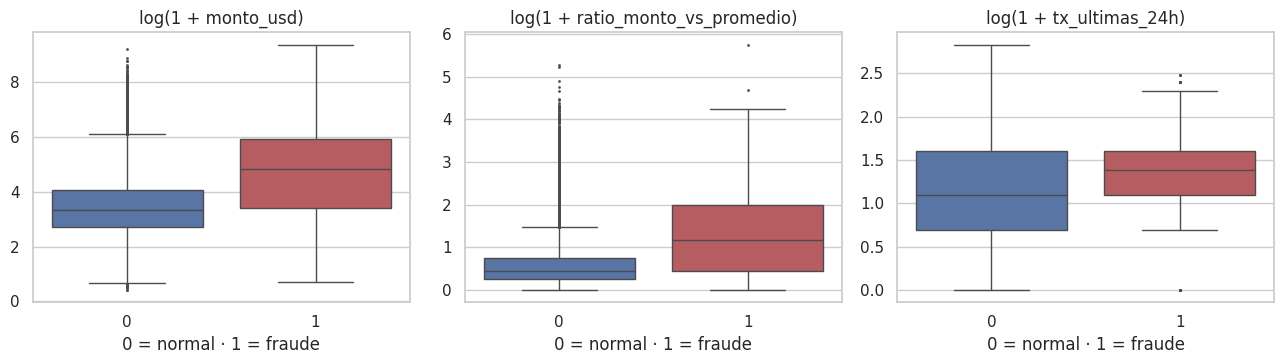

In [9]:
def outliers_iqr(s):
    q1, q3 = s.quantile([.25,.75]); iqr = q3 - q1
    return ((s < q1-1.5*iqr) | (s > q3+1.5*iqr)).mean()*100
out = pd.DataFrame({'% outliers (IQR)': [outliers_iqr(df[c].dropna()) for c in num_cols]}, index=num_cols).round(2)
out['% fraude dentro de los outliers'] = [
    df.loc[df[c].notna(), 'es_fraude'][(lambda s,q1,q3: (s<q1-1.5*(q3-q1))|(s>q3+1.5*(q3-q1)))(df[c].dropna(), *df[c].dropna().quantile([.25,.75]))].mean()*100
    for c in num_cols]
display(out.round(2))

fig, ax = plt.subplots(1, 3, figsize=(13,3.8))
for a, c in zip(ax, ['monto_usd','ratio_monto_vs_promedio','tx_ultimas_24h']):
    sns.boxplot(data=df, x='es_fraude', y=np.log1p(df[c]), ax=a, showfliers=True, fliersize=1, palette=['#4C72B0','#C44E52'])
    a.set_title(f'log(1 + {c})'); a.set_xlabel('0 = normal · 1 = fraude'); a.set_ylabel('')
plt.tight_layout(); plt.savefig(FIG/'03_outliers_boxplot.png', dpi=150); plt.show()

**Explicación del código:** con la regla del rango intercuartílico (IQR) se mide qué porcentaje de valores queda fuera de los "bigotes" en cada variable, y qué parte de esos outliers son fraude. Los boxplots en escala logarítmica comparan monto, razón vs. promedio y ráfagas de 24 h entre clases. Sirve para distinguir outliers estadísticos (por ejemplo, compras grandes de clientes Pymes) de anomalías relevantes.

## Paso 9. Fraude por hora, canal y tipo de comercio

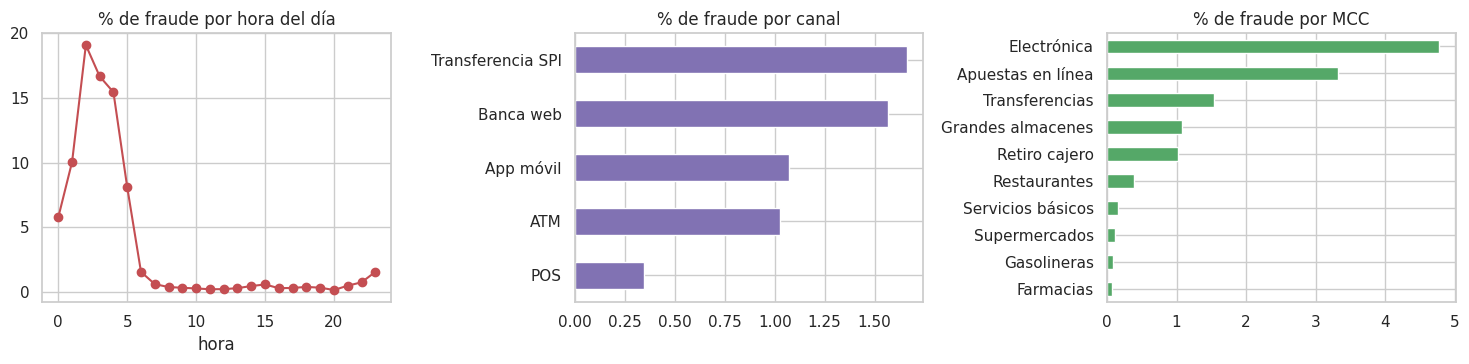

In [10]:
df['hora'] = df.fecha_hora.dt.hour
fig, ax = plt.subplots(1, 3, figsize=(15,3.8))
(df.groupby('hora').es_fraude.mean()*100).plot(ax=ax[0], marker='o', color='#C44E52', title='% de fraude por hora del día')
(df.groupby('canal').es_fraude.mean()*100).sort_values().plot.barh(ax=ax[1], color='#8172B3', title='% de fraude por canal')
(df.groupby('descripcion_mcc').es_fraude.mean()*100).sort_values().plot.barh(ax=ax[2], color='#55A868', title='% de fraude por MCC')
for a in ax: a.set_ylabel('')
plt.tight_layout(); plt.savefig(FIG/'04_fraude_hora_canal_mcc.png', dpi=150); plt.show()

**Explicación del código:** calcula la tasa de fraude por hora, por canal y por tipo de comercio. Se observa que la madrugada, la banca web, las transferencias SPI, la electrónica y las apuestas en línea concentran el riesgo.

## Paso 10. Matriz de correlación

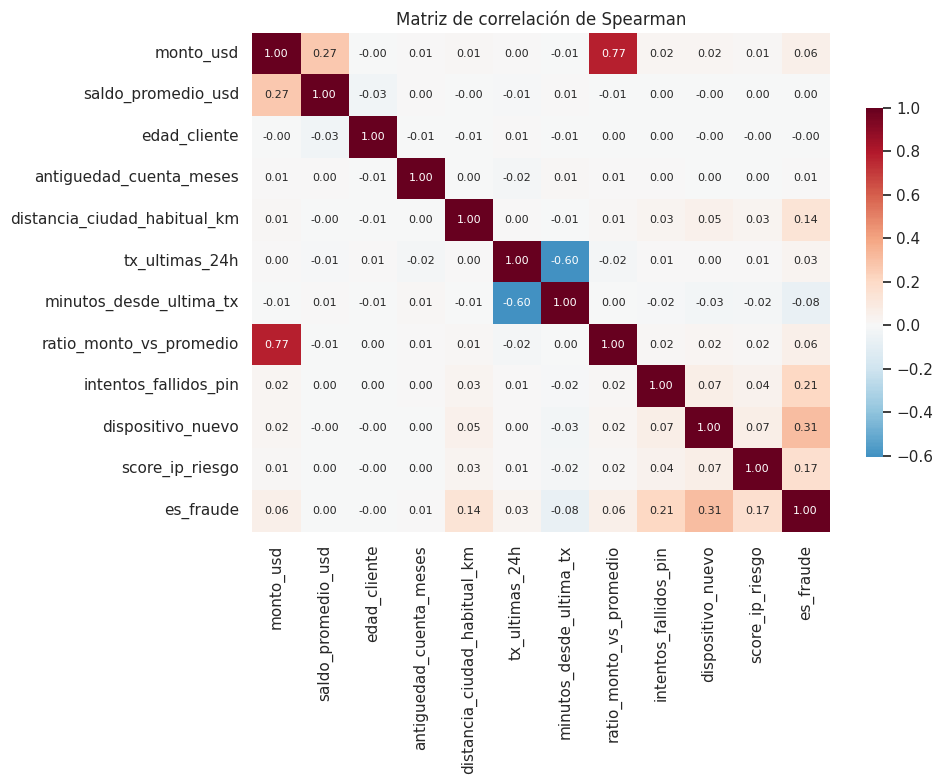

,corr. con fraude
dispositivo_nuevo,0.306
intentos_fallidos_pin,0.206
score_ip_riesgo,0.167
distancia_ciudad_habitual_km,0.136
minutos_desde_ultima_tx,-0.076
monto_usd,0.062
ratio_monto_vs_promedio,0.059
tx_ultimas_24h,0.026
antiguedad_cuenta_meses,0.006
edad_cliente,-0.002


In [11]:
corr = df[num_cols + ['es_fraude']].corr(method='spearman')
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, annot_kws={'size':8}, cbar_kws={'shrink':.7})
plt.title('Matriz de correlación de Spearman'); plt.tight_layout()
plt.savefig(FIG/'05_matriz_correlacion.png', dpi=150); plt.show()
display(corr['es_fraude'].drop('es_fraude').sort_values(key=abs, ascending=False).round(3).to_frame('corr. con fraude'))

**Explicación del código:** calcula la correlación de Spearman (adecuada para variables sesgadas como el monto) entre todas las variables numéricas y la etiqueta de fraude, la muestra como mapa de calor y ordena las variables por su relación con el fraude.

## Paso 11. Ingeniería de variables para el modelo

In [12]:
df['es_nocturna'] = df.hora.between(0,5).astype(int)
df['fuera_ciudad'] = (df.distancia_ciudad_habitual_km > 0).astype(int)
df['score_ip_faltante'] = df.score_ip_riesgo.isna().astype(int)
df['hora_sin'] = np.sin(2*np.pi*df.hora/24); df['hora_cos'] = np.cos(2*np.pi*df.hora/24)
for c in ['monto_usd','saldo_promedio_usd','ratio_monto_vs_promedio','minutos_desde_ultima_tx','distancia_ciudad_habitual_km']:
    df['log_'+c] = np.log1p(df[c])

NUM = ['log_monto_usd','log_ratio_monto_vs_promedio','log_minutos_desde_ultima_tx','log_distancia_ciudad_habitual_km',
       'log_saldo_promedio_usd','tx_ultimas_24h','intentos_fallidos_pin','score_ip_riesgo','edad_cliente',
       'antiguedad_cuenta_meses','hora_sin','hora_cos']
BIN = ['dispositivo_nuevo','es_nocturna','fuera_ciudad','score_ip_faltante']
CAT = ['canal','mcc','segmento','tipo_tarjeta']
FEATS = NUM + BIN + CAT
print(len(NUM), 'numéricas |', len(BIN), 'binarias |', len(CAT), 'categóricas')

12 numéricas | 4 binarias | 4 categóricas


**Explicación del código:**
- Se crean indicadores binarios (transacción nocturna, fuera de la ciudad, score de IP ausente).
- La hora se transforma con seno y coseno para que el modelo entienda que las 23h y las 0h están juntas.
- Montos, razones, distancias y tiempos se transforman con `log1p` porque tienen colas muy largas.
- Se definen las listas de variables numéricas, binarias y categóricas que entran al modelo. No se usan IDs, fechas ni ciudades en texto para evitar que el modelo memorice clientes o discrimine por ubicación.

## Paso 12. Partición temporal: entrenamiento, validación y prueba

In [13]:
dia = df.fecha_hora.dt.day
train, val, test = df[dia <= 21], df[(dia > 21) & (dia <= 25)], df[dia > 25]
particion = pd.DataFrame({'días':['1-21','22-25','26-30'],
    'transacciones':[len(train),len(val),len(test)],
    'fraudes':[train.es_fraude.sum(), val.es_fraude.sum(), test.es_fraude.sum()],
    '% fraude':[round(x.es_fraude.mean()*100,3) for x in (train,val,test)]}, index=['Entrenamiento','Validación','Prueba'])
display(particion)

,días,transacciones,fraudes,% fraude
Entrenamiento,1-21,130002,919,0.707
Validación,22-25,24695,205,0.830
Prueba,26-30,30787,250,0.812


**Explicación del código:** divide los datos por fecha y no al azar: se entrena con lo ocurrido del 1 al 21 de septiembre, se calibran umbrales con los días 22-25 y se evalúa con los días 26-30. Así se simula un sistema que se entrena con el pasado y opera sobre transacciones futuras, evitando fuga de información.

## Paso 13. Pipeline de preprocesamiento y estrategia de desbalance

In [14]:
preprocesador = ColumnTransformer([
    ('num', Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]), NUM),
    ('bin', 'passthrough', BIN),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)])

# Se ajusta solo con transacciones normales de entrenamiento (referencia de "normalidad")
preprocesador.fit(train.loc[train.es_fraude == 0, FEATS])
X_tr, X_va, X_te = (preprocesador.transform(d[FEATS]) for d in (train, val, test))
y_tr, y_va, y_te = train.es_fraude.values, val.es_fraude.values, test.es_fraude.values
X_normal = X_tr[y_tr == 0]
nombres = preprocesador.get_feature_names_out()
print('Matriz de entrenamiento:', X_tr.shape, '| solo normales:', X_normal.shape)

Matriz de entrenamiento: (130002, 36) | solo normales: (129083, 36)


**Explicación del código:**
- **Faltantes:** las numéricas se imputan con la mediana (robusta a outliers) y se conserva la bandera `score_ip_faltante`, que también aporta información.
- **Escalado:** `StandardScaler` deja cada variable con media 0 y desviación 1; es necesario para LOF, One-Class SVM y el autoencoder, que trabajan con distancias o gradientes.
- **Categóricas:** `OneHotEncoder` convierte canal, MCC, segmento y tipo de tarjeta en columnas 0/1; `handle_unknown='ignore'` evita errores si en producción aparece una categoría nueva.
- El preprocesador se ajusta solo con transacciones normales de entrenamiento, que es la "normalidad" que aprenden los modelos no supervisados.

In [15]:
def mejor_umbral(y, s):
    p, r, t = precision_recall_curve(y, s); f = 2*p*r/(p+r+1e-12)
    return t[np.nanargmax(f[:-1])]

COLS_DISCRETAS = np.array([n.startswith(('bin__', 'cat__')) for n in nombres])   # binarias y one-hot

def smote(X, y, proporcion=.10, k=5, seed=SEED):
    # SMOTE (Chawla et al., 2002) con tratamiento categórico al estilo SMOTE-NC:
    # las numéricas se interpolan y las binarias/one-hot se copian del fraude original
    r = np.random.default_rng(seed); Xm = X[y == 1]
    n_nuevos = int(proporcion*(y == 0).sum()) - len(Xm)
    _, ind = NearestNeighbors(n_neighbors=k+1).fit(Xm[:, ~COLS_DISCRETAS]).kneighbors(Xm[:, ~COLS_DISCRETAS])
    i = r.integers(0, len(Xm), n_nuevos); j = ind[i, r.integers(1, k+1, n_nuevos)]
    nuevos = Xm[i] + r.random((n_nuevos,1))*(Xm[j]-Xm[i])
    nuevos[:, COLS_DISCRETAS] = Xm[i][:, COLS_DISCRETAS]                    # categorías siempre válidas (0/1)
    return np.vstack([X, nuevos]), np.r_[y, np.ones(n_nuevos, int)]

idx_n = np.flatnonzero(y_tr == 0); idx_f = np.flatnonzero(y_tr == 1)
idx_under = np.r_[idx_f, rng.choice(idx_n, len(idx_n)//10, replace=False)]
estrategias = {'Sin tratamiento':(X_tr, y_tr, None), 'Ponderación de clases':(X_tr, y_tr, 'balanced'),
               'SMOTE-NC (10 %)':(*smote(X_tr, y_tr), None), 'Undersampling (10 % normales)':(X_tr[idx_under], y_tr[idx_under], None)}
filas = []
for nombre, (Xa, ya, cw) in estrategias.items():
    t = time.perf_counter()
    m = HistGradientBoostingClassifier(class_weight=cw, max_iter=300, learning_rate=.05, random_state=SEED).fit(Xa, ya)
    s = m.predict_proba(X_va)[:,1]
    filas.append([nombre, len(ya), round(average_precision_score(y_va, s),4), round(roc_auc_score(y_va, s),4),
                  round(f1_score(y_va, s >= mejor_umbral(y_va, s)),4), round(time.perf_counter()-t,1)])
tabla_desb = pd.DataFrame(filas, columns=['Estrategia','filas entrenamiento','AUC-PR val','AUC-ROC val','F1 val','seg. entrenamiento']).set_index('Estrategia')
display(tabla_desb); tabla_desb.to_csv(RES/'comparacion_desbalance.csv')

,filas entrenamiento,AUC-PR val,AUC-ROC val,F1 val,seg. entrenamiento
Estrategia,,,,,
Sin tratamiento,130002,0.8739,0.9835,0.8401,9.8
Ponderación de clases,130002,0.8269,0.9848,0.8209,4.6
SMOTE-NC (10 %),141991,0.8717,0.9853,0.8497,17.3
Undersampling (10 % normales),13827,0.8651,0.9856,0.8389,2.6


**Explicación del código:**
- `mejor_umbral` busca el punto de corte del score que maximiza el F1 en un conjunto con etiquetas.
- `smote` crea fraudes sintéticos interpolando las variables numéricas entre un fraude real y un vecino fraudulento. Las variables binarias y las columnas one-hot no se interpolan (eso daría valores como 0,4 de "App móvil", que no existen): se copian del fraude original, como hace SMOTE-NC. Así cada registro sintético tiene categorías válidas.
- Se compara, con el mismo clasificador y midiendo en validación, entrenar sin tratamiento, con ponderación de clases, con SMOTE y con submuestreo. Las cuatro estrategias quedan cerca entre sí (el AUC-PR varía entre 0,84 y 0,87). Se elige **SMOTE-NC** para el modelo supervisado del Paso 19: está en el grupo con mejor AUC-PR, conserva todas las transacciones reales (el submuestreo descarta el 90 % de las normales) y sus registros sintéticos tienen categorías válidas. Que entrenar sin tratamiento dé un resultado parecido indica que el boosting tolera bien el desbalance cuando las variables son informativas.
- Para los modelos no supervisados el desbalance se aborda de otra forma: se entrenan solo con transacciones normales (enfoque semisupervisado).

# FASE 2 · Implementación y evaluación de modelos

## Paso 14. Función de evaluación común

In [16]:
LOTE = X_te[:10_000]          # lote de 10.000 transacciones del requisito de latencia
LOTE_CRUDO = test[FEATS].iloc[:10_000]
resultados, scores_test = {}, {}

def evaluar(nombre, score_fn, repeticiones=5):
    umbral = mejor_umbral(y_va, score_fn(X_va))            # calibrado en validación
    s = score_fn(X_te); y_pred = (s >= umbral).astype(int)
    t_mod, t_total = [], []
    for _ in range(repeticiones):
        t = time.perf_counter(); score_fn(LOTE); t_mod.append(time.perf_counter()-t)
        t = time.perf_counter(); score_fn(preprocesador.transform(LOTE_CRUDO)); t_total.append(time.perf_counter()-t)
    resultados[nombre] = {'Precision':precision_score(y_te, y_pred), 'Recall':recall_score(y_te, y_pred),
        'F1 (fraude)':f1_score(y_te, y_pred), 'F1 macro':f1_score(y_te, y_pred, average='macro'),
        'F1 ponderado':f1_score(y_te, y_pred, average='weighted'), 'AUC-ROC':roc_auc_score(y_te, s),
        'AUC-PR':average_precision_score(y_te, s), 'ms modelo / 10k':1000*np.median(t_mod),
        'ms pipeline / 10k':1000*np.median(t_total), 'Alertas':int(y_pred.sum())}
    scores_test[nombre] = s
    print(nombre, {k: round(v,3) for k,v in resultados[nombre].items()})

**Explicación del código:** define una función única para evaluar todos los modelos igual:
1. Calcula el umbral óptimo en validación.
2. Clasifica el conjunto de prueba y calcula Precision, Recall, F1 de la clase fraude, F1 macro, F1 ponderado, AUC-ROC y AUC-PR.
3. Mide el tiempo de inferencia de un lote de 10.000 transacciones (mediana de 5 repeticiones), solo del modelo y del pipeline completo con preprocesamiento.

## Paso 15. Modelo 1 – Isolation Forest

In [17]:
t = time.perf_counter()
iforest = IsolationForest(n_estimators=200, max_samples=256, contamination='auto', random_state=SEED, n_jobs=-1).fit(X_normal)
print(f'Entrenamiento: {time.perf_counter()-t:.1f} s')
evaluar('Isolation Forest', lambda Z: -iforest.score_samples(Z))

Entrenamiento: 0.8 s
Isolation Forest {'Precision': 0.598, 'Recall': 0.588, 'F1 (fraude)': 0.593, 'F1 macro': 0.795, 'F1 ponderado': 0.993, 'AUC-ROC': np.float64(0.961), 'AUC-PR': np.float64(0.614), 'ms modelo / 10k': np.float64(143.142), 'ms pipeline / 10k': np.float64(170.468), 'Alertas': 246}


**Explicación del código:**
- **Arquitectura:** bosque de 200 árboles de aislamiento; cada árbol usa 256 transacciones al azar y corta variables en puntos aleatorios.
- **Score:** las transacciones que se aíslan con pocos cortes (camino corto) son más anómalas; `score_samples` se invierte para que valor alto = más sospechoso.
- **Entrenamiento:** solo con transacciones normales de entrenamiento; el umbral se fija en validación.

## Paso 16. Modelo 2 – Local Outlier Factor (LOF)

In [18]:
idx = rng.choice(len(X_normal), 40_000, replace=False)
t = time.perf_counter()
lof = LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=-1).fit(X_normal[idx])
print(f'Entrenamiento: {time.perf_counter()-t:.1f} s')
evaluar('LOF', lambda Z: -lof.score_samples(Z))

Entrenamiento: 15.1 s
LOF {'Precision': 0.711, 'Recall': 0.54, 'F1 (fraude)': 0.614, 'F1 macro': 0.805, 'F1 ponderado': 0.994, 'AUC-ROC': np.float64(0.956), 'AUC-PR': np.float64(0.634), 'ms modelo / 10k': np.float64(4017.532), 'ms pipeline / 10k': np.float64(3437.481), 'Alertas': 190}


**Explicación del código:**
- **Arquitectura:** compara la densidad local de cada transacción con la de sus 35 vecinos más cercanos; si está en una zona mucho menos densa, es anómala.
- `novelty=True` permite puntuar transacciones nuevas (necesario en streaming).
- Se entrena con una muestra de 40.000 normales porque el costo de buscar vecinos crece con el tamaño de la referencia.

## Paso 17. Modelo 3 – Autoencoder con capas densas

Entrenamiento: 22.0 s | épocas: 47 | pérdida final: 0.0370
Autoencoder denso {'Precision': 0.743, 'Recall': 0.544, 'F1 (fraude)': 0.628, 'F1 macro': 0.813, 'F1 ponderado': 0.994, 'AUC-ROC': np.float64(0.967), 'AUC-PR': np.float64(0.653), 'ms modelo / 10k': np.float64(9.511), 'ms pipeline / 10k': np.float64(60.978), 'Alertas': 183}


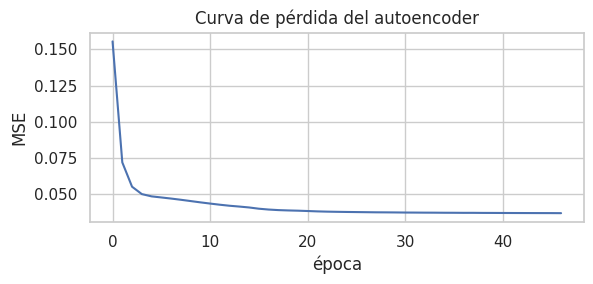

In [19]:
t = time.perf_counter()
autoencoder = MLPRegressor(hidden_layer_sizes=(24, 8, 24), activation='relu', solver='adam', learning_rate_init=1e-3,
                           batch_size=512, max_iter=60, early_stopping=True, validation_fraction=.1, random_state=SEED)
autoencoder.fit(X_normal, X_normal)
print(f'Entrenamiento: {time.perf_counter()-t:.1f} s | épocas: {autoencoder.n_iter_} | pérdida final: {autoencoder.loss_:.4f}')
error_reconstruccion = lambda Z: ((autoencoder.predict(Z) - Z)**2).mean(axis=1)
evaluar('Autoencoder denso', error_reconstruccion)

plt.figure(figsize=(6,3)); plt.plot(autoencoder.loss_curve_, color='#4C72B0')
plt.title('Curva de pérdida del autoencoder'); plt.xlabel('época'); plt.ylabel('MSE'); plt.tight_layout(); plt.show()

**Explicación del código:**
- **Arquitectura:** red neuronal 36 → 24 → **8** → 24 → 36 con activación ReLU. La capa de 8 neuronas es el cuello de botella que obliga a comprimir la información.
- **Entrenamiento:** la red aprende a reproducir su propia entrada usando solo transacciones normales (optimizador Adam, lotes de 512, hasta 60 épocas con parada temprana).
- **Score:** el error cuadrático medio de reconstrucción; un fraude, al ser distinto a lo aprendido, se reconstruye peor.
- Se implementa con `MLPRegressor` de scikit-learn, equivalente a un autoencoder denso de Keras.

## Paso 18. Modelo 4 – One-Class SVM

In [20]:
idx = rng.choice(len(X_normal), 15_000, replace=False)
t = time.perf_counter()
ocsvm = OneClassSVM(kernel='rbf', nu=.01, gamma='scale').fit(X_normal[idx])
print(f'Entrenamiento: {time.perf_counter()-t:.1f} s | vectores de soporte: {ocsvm.support_vectors_.shape[0]}')
evaluar('One-Class SVM', lambda Z: -ocsvm.score_samples(Z))

Entrenamiento: 0.5 s | vectores de soporte: 286
One-Class SVM {'Precision': 0.694, 'Recall': 0.572, 'F1 (fraude)': 0.627, 'F1 macro': 0.812, 'F1 ponderado': 0.994, 'AUC-ROC': np.float64(0.937), 'AUC-PR': np.float64(0.637), 'ms modelo / 10k': np.float64(355.695), 'ms pipeline / 10k': np.float64(401.294), 'Alertas': 206}


**Explicación del código:**
- **Arquitectura:** kernel RBF que traza una frontera alrededor de la región de transacciones normales; lo que queda fuera es anómalo.
- `nu=0.01` limita la fracción de normales que pueden quedar fuera de la frontera; `gamma='scale'` ajusta el ancho del kernel según la varianza de los datos.
- Se entrena con 15.000 normales porque el costo del SVM crece casi cuadráticamente con el número de filas.

## Paso 19. Modelo de referencia supervisado – HistGradientBoosting

In [21]:
X_smote, y_smote = smote(X_tr, y_tr)                  # estrategia elegida en el Paso 13
t = time.perf_counter()
hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=.05, max_leaf_nodes=31,
                                     random_state=SEED).fit(X_smote, y_smote)
print(f'Entrenamiento: {time.perf_counter()-t:.1f} s | árboles: {hgb.n_iter_}')
evaluar('HistGradientBoosting (supervisado)', lambda Z: hgb.predict_proba(Z)[:,1])

# Híbrido: HGB (fraude conocido) + Autoencoder (patrones nuevos) con umbral muy alto
umbral_hgb = mejor_umbral(y_va, hgb.predict_proba(X_va)[:,1])
umbral_ae = np.percentile(error_reconstruccion(X_normal), 99.9)
def score_hibrido(Z):
    return np.maximum(hgb.predict_proba(Z)[:,1]/umbral_hgb, error_reconstruccion(Z)/umbral_ae)
evaluar('Híbrido HGB + Autoencoder', score_hibrido)

Entrenamiento: 15.6 s | árboles: 300
HistGradientBoosting (supervisado) {'Precision': 0.867, 'Recall': 0.784, 'F1 (fraude)': 0.824, 'F1 macro': 0.911, 'F1 ponderado': 0.997, 'AUC-ROC': np.float64(0.994), 'AUC-PR': np.float64(0.898), 'ms modelo / 10k': np.float64(360.306), 'ms pipeline / 10k': np.float64(393.279), 'Alertas': 226}
Híbrido HGB + Autoencoder {'Precision': 0.896, 'Recall': 0.756, 'F1 (fraude)': 0.82, 'F1 macro': 0.909, 'F1 ponderado': 0.997, 'AUC-ROC': np.float64(0.978), 'AUC-PR': np.float64(0.821), 'ms modelo / 10k': np.float64(381.84), 'ms pipeline / 10k': np.float64(414.505), 'Alertas': 211}


**Explicación del código:**
- Se entrena un clasificador de gradient boosting por histogramas (familia de XGBoost/LightGBM) con las etiquetas, usando el conjunto balanceado con **SMOTE**, como referencia de lo que se logra cuando el banco sí tiene casos de fraude confirmados.
- El **híbrido** normaliza cada score por su umbral y alerta si cualquiera de los dos lo supera: el boosting detecta patrones de fraude ya conocidos y el autoencoder (el no supervisado más rápido y con mejor AUC-PR), con un umbral muy exigente (percentil 99,9 de las normales), sirve de red de seguridad ante comportamientos nuevos sin etiqueta.

## Paso 20. Tabla comparativa de resultados

In [22]:
tabla = pd.DataFrame(resultados).T
tabla_fmt = tabla.copy()
for c in tabla.columns:
    tabla_fmt[c] = tabla[c].round(1 if c.startswith('ms') else 0 if c == 'Alertas' else 3)
tabla_fmt['Cumple 500 ms'] = np.where(tabla['ms pipeline / 10k'] <= 500, 'Sí', 'No')
display(tabla_fmt)
tabla_fmt.to_csv(RES/'tabla_comparativa_modelos.csv')
print('Fraudes reales en prueba:', y_te.sum(), 'de', len(y_te))

,Precision,Recall,F1 (fraude),F1 macro,F1 ponderado,AUC-ROC,AUC-PR,ms modelo / 10k,ms pipeline / 10k,Alertas,Cumple 500 ms
Isolation Forest,0.598,0.588,0.593,0.795,0.993,0.961,0.614,143.1,170.5,246.0,Sí
LOF,0.711,0.540,0.614,0.805,0.994,0.956,0.634,4017.5,3437.5,190.0,No
Autoencoder denso,0.743,0.544,0.628,0.813,0.994,0.967,0.653,9.5,61.0,183.0,Sí
One-Class SVM,0.694,0.572,0.627,0.812,0.994,0.937,0.637,355.7,401.3,206.0,Sí
HistGradientBoosting (supervisado),0.867,0.784,0.824,0.911,0.997,0.994,0.898,360.3,393.3,226.0,Sí
Híbrido HGB + Autoencoder,0.896,0.756,0.820,0.909,0.997,0.978,0.821,381.8,414.5,211.0,Sí


Fraudes reales en prueba: 250 de 30787


**Explicación del código:** reúne todas las métricas en una sola tabla, redondea, marca si cada modelo cumple la restricción de 500 ms por lote de 10.000 y la guarda en `resultados/tabla_comparativa_modelos.csv`.

## Paso 21. Curvas ROC y Precision-Recall

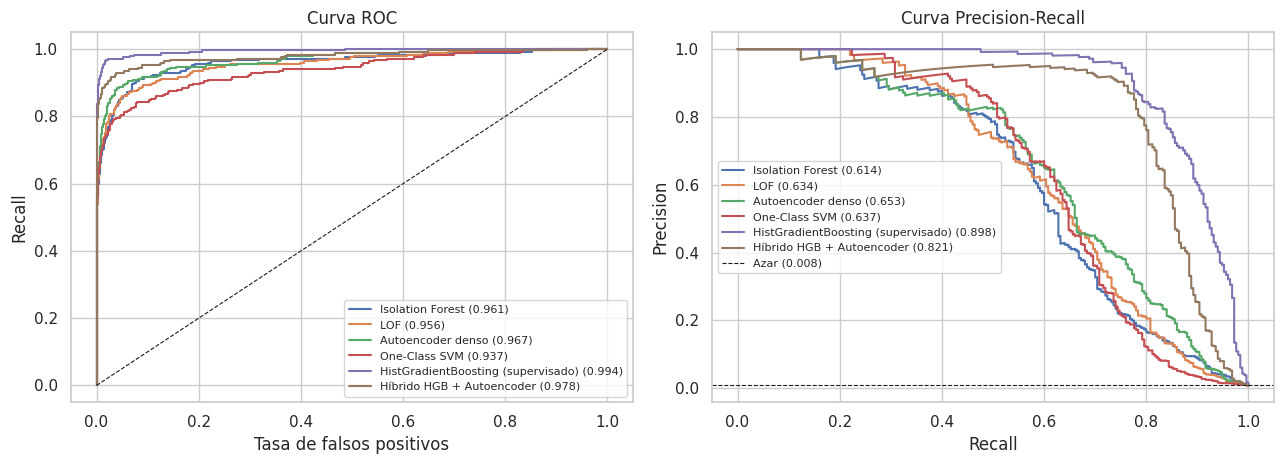

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13,4.8))
for nombre, s in scores_test.items():
    fpr, tpr, _ = roc_curve(y_te, s); p, r, _ = precision_recall_curve(y_te, s)
    ax[0].plot(fpr, tpr, label=f'{nombre} ({roc_auc_score(y_te,s):.3f})')
    ax[1].plot(r, p, label=f'{nombre} ({average_precision_score(y_te,s):.3f})')
ax[0].plot([0,1],[0,1],'k--',lw=.8); ax[0].set(title='Curva ROC', xlabel='Tasa de falsos positivos', ylabel='Recall')
ax[1].axhline(y_te.mean(), color='k', ls='--', lw=.8, label=f'Azar ({y_te.mean():.3f})')
ax[1].set(title='Curva Precision-Recall', xlabel='Recall', ylabel='Precision')
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG/'06_curvas_roc_pr.png', dpi=150); plt.show()

**Explicación del código:** dibuja las curvas ROC y Precision-Recall de todos los modelos sobre el conjunto de prueba. La línea de azar en la curva PR es la proporción de fraude (~0,9 %); por eso la curva PR muestra con más claridad las diferencias entre modelos que la ROC, donde todos parecen buenos.

## Paso 22. Matrices de confusión

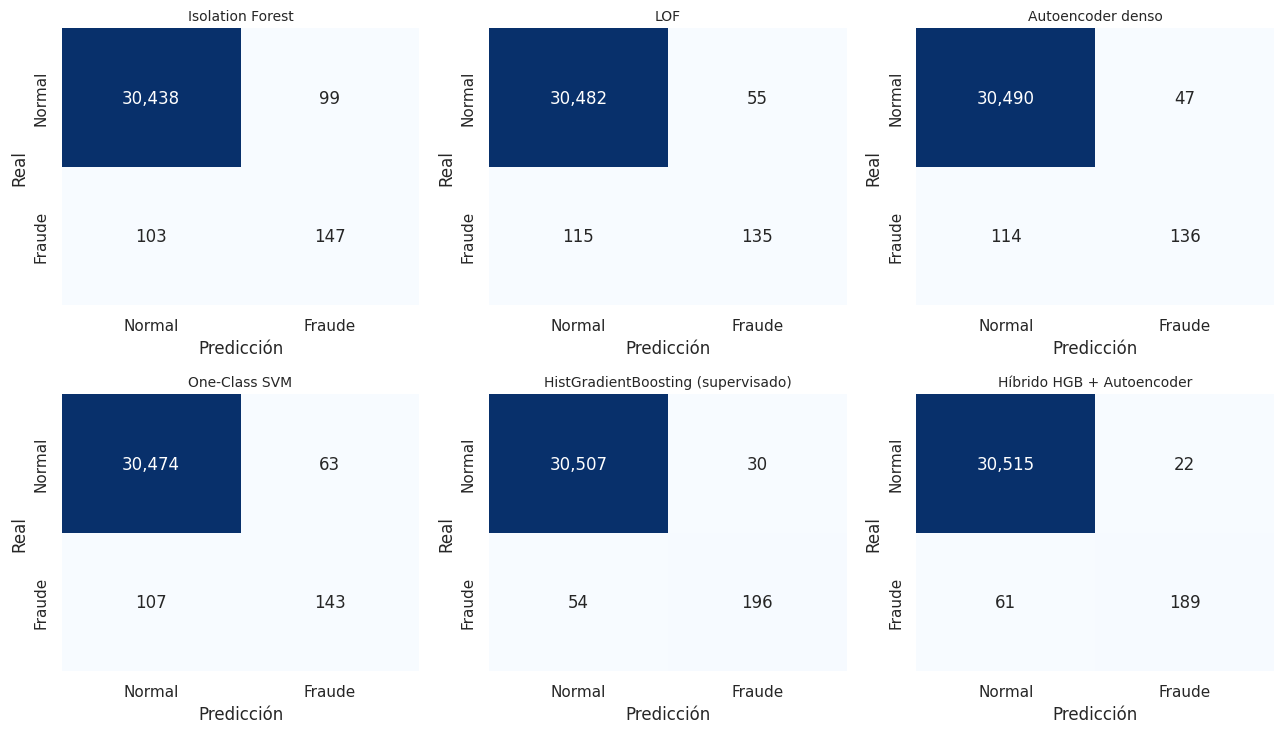

In [24]:
fig, ax = plt.subplots(2, 3, figsize=(13,7.5))
for a, (nombre, s) in zip(ax.ravel(), scores_test.items()):
    fn = {'Isolation Forest':lambda Z:-iforest.score_samples(Z), 'LOF':lambda Z:-lof.score_samples(Z),
          'Autoencoder denso':error_reconstruccion, 'One-Class SVM':lambda Z:-ocsvm.score_samples(Z),
          'HistGradientBoosting (supervisado)':lambda Z:hgb.predict_proba(Z)[:,1], 'Híbrido HGB + Autoencoder':score_hibrido}[nombre]
    cm = confusion_matrix(y_te, s >= mejor_umbral(y_va, fn(X_va)))
    sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', cbar=False, ax=a,
                xticklabels=['Normal','Fraude'], yticklabels=['Normal','Fraude'])
    a.set_title(nombre, fontsize=10); a.set_xlabel('Predicción'); a.set_ylabel('Real')
plt.tight_layout(); plt.savefig(FIG/'07_matrices_confusion.png', dpi=150); plt.show()

**Explicación del código:** muestra para cada modelo cuántos fraudes se detectaron (verdaderos positivos), cuántos se escaparon (falsos negativos) y cuántas transacciones legítimas se marcaron por error (falsos positivos), con el mismo umbral de validación usado en la tabla.

## Paso 23. Relación desempeño / latencia

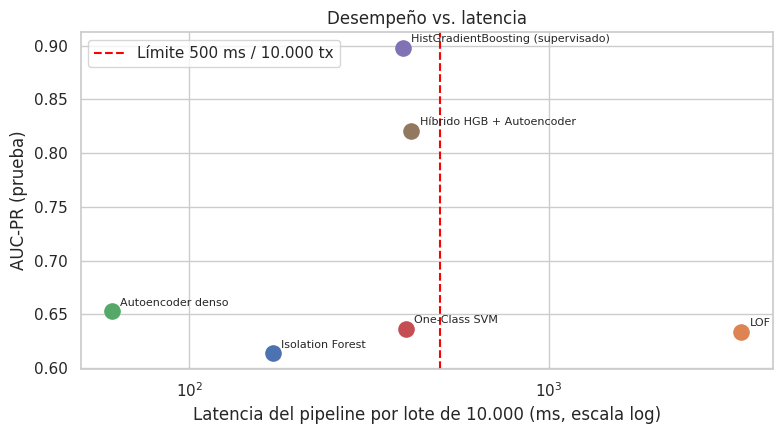

In [25]:
plt.figure(figsize=(8,4.5))
for nombre, fila in tabla.iterrows():
    plt.scatter(fila['ms pipeline / 10k'], fila['AUC-PR'], s=120)
    plt.annotate(nombre, (fila['ms pipeline / 10k'], fila['AUC-PR']), textcoords='offset points', xytext=(6,4), fontsize=8)
plt.axvline(500, color='red', ls='--', label='Límite 500 ms / 10.000 tx')
plt.xscale('log'); plt.xlabel('Latencia del pipeline por lote de 10.000 (ms, escala log)'); plt.ylabel('AUC-PR (prueba)')
plt.title('Desempeño vs. latencia'); plt.legend(); plt.tight_layout()
plt.savefig(FIG/'08_desempeno_vs_latencia.png', dpi=150); plt.show()

**Explicación del código:** ubica cada modelo según su AUC-PR (eje vertical) y su latencia por lote (eje horizontal, escala logarítmica), con la línea roja del límite de 500 ms. El mejor equilibrio es el modelo más alto que quede a la izquierda de la línea.

# FASE 3 · Diseño del pipeline de streaming

## Paso 24. Diagrama de arquitectura (Kafka + Flink)

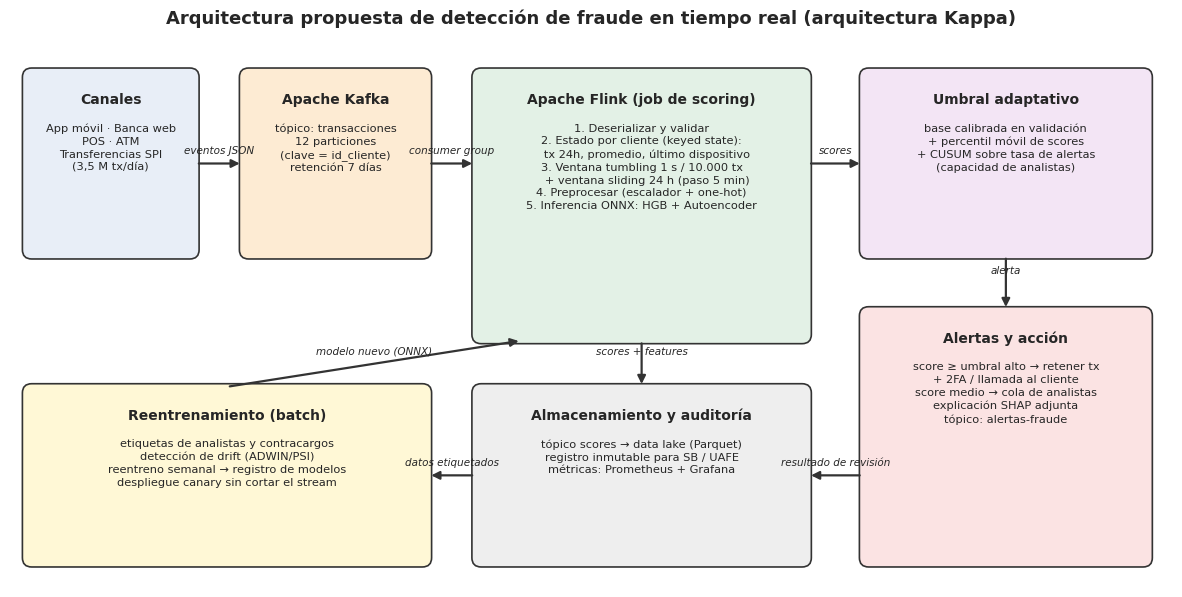

In [26]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(15,7.2)); ax.set_xlim(0,15); ax.set_ylim(0,7.2); ax.axis('off')
def caja(x, y, w, h, titulo, texto, color):
    ax.add_patch(FancyBboxPatch((x,y), w, h, boxstyle='round,pad=0.04,rounding_size=0.12', fc=color, ec='#333', lw=1.2))
    ax.text(x+w/2, y+h-.28, titulo, ha='center', va='top', fontsize=10, weight='bold')
    ax.text(x+w/2, y+h-.68, texto, ha='center', va='top', fontsize=8.2, linespacing=1.35)
def flecha(x1, y1, x2, y2, txt=''):
    ax.annotate('', (x2,y2), (x1,y1), arrowprops=dict(arrowstyle='-|>', lw=1.6, color='#333'))
    if txt: ax.text((x1+x2)/2, (y1+y2)/2+.12, txt, ha='center', fontsize=7.5, style='italic')
caja(.2, 4.3, 2.2, 2.4, 'Canales', 'App móvil · Banca web\nPOS · ATM\nTransferencias SPI\n(3,5 M tx/día)', '#E8EEF7')
caja(3.0, 4.3, 2.4, 2.4, 'Apache Kafka', 'tópico: transacciones\n12 particiones\n(clave = id_cliente)\nretención 7 días', '#FDEBD3')
caja(6.0, 3.2, 4.3, 3.5, 'Apache Flink (job de scoring)', '1. Deserializar y validar\n2. Estado por cliente (keyed state):\n   tx 24h, promedio, último dispositivo\n3. Ventana tumbling 1 s / 10.000 tx\n   + ventana sliding 24 h (paso 5 min)\n4. Preprocesar (escalador + one-hot)\n5. Inferencia ONNX: HGB + Autoencoder', '#E3F1E6')
caja(11.0, 4.3, 3.7, 2.4, 'Umbral adaptativo', 'base calibrada en validación\n+ percentil móvil de scores\n+ CUSUM sobre tasa de alertas\n(capacidad de analistas)', '#F3E5F5')
caja(11.0, .3, 3.7, 3.3, 'Alertas y acción', 'score ≥ umbral alto → retener tx\n+ 2FA / llamada al cliente\nscore medio → cola de analistas\nexplicación SHAP adjunta\ntópico: alertas-fraude', '#FBE3E3')
caja(6.0, .3, 4.3, 2.3, 'Almacenamiento y auditoría', 'tópico scores → data lake (Parquet)\nregistro inmutable para SB / UAFE\nmétricas: Prometheus + Grafana', '#EEEEEE')
caja(.2, .3, 5.2, 2.3, 'Reentrenamiento (batch)', 'etiquetas de analistas y contracargos\ndetección de drift (ADWIN/PSI)\nreentreno semanal → registro de modelos\ndespliegue canary sin cortar el stream', '#FFF8D6')
flecha(2.4, 5.5, 3.0, 5.5, 'eventos JSON'); flecha(5.4, 5.5, 6.0, 5.5, 'consumer group')
flecha(10.3, 5.5, 11.0, 5.5, 'scores'); flecha(12.85, 4.3, 12.85, 3.6, 'alerta')
flecha(8.15, 3.2, 8.15, 2.6, 'scores + features'); flecha(6.0, 1.45, 5.4, 1.45, 'datos etiquetados')
flecha(2.8, 2.6, 6.6, 3.2, 'modelo nuevo (ONNX)'); flecha(11.0, 1.45, 10.3, 1.45, 'resultado de revisión')
ax.set_title('Arquitectura propuesta de detección de fraude en tiempo real (arquitectura Kappa)', fontsize=13, weight='bold')
plt.savefig(FIG/'09_arquitectura_streaming.png', dpi=170, bbox_inches='tight'); plt.show()

**Explicación del código:** dibuja el diagrama de flujo del pipeline propuesto: los canales publican eventos en Kafka; Flink mantiene el estado por cliente, aplica ventanas tumbling (lotes) y sliding (comportamiento de 24 h), preprocesa y ejecuta los modelos exportados en ONNX; un módulo de umbral adaptativo decide las alertas, que van a acción inmediata o a analistas; todo queda registrado para auditoría y alimenta el reentrenamiento.

## Paso 25. Simulación de streaming con ventanas tumbling y umbral adaptativo

Umbral base del híbrido (calibrado en validación): 1.308
Ventanas procesadas: 480 | tx por ventana (media): 64 | latencia media: 15.6 ms | p99: 65.5 ms
Recall en streaming: 0.688 | Precision: 0.891 | alertas totales: 193


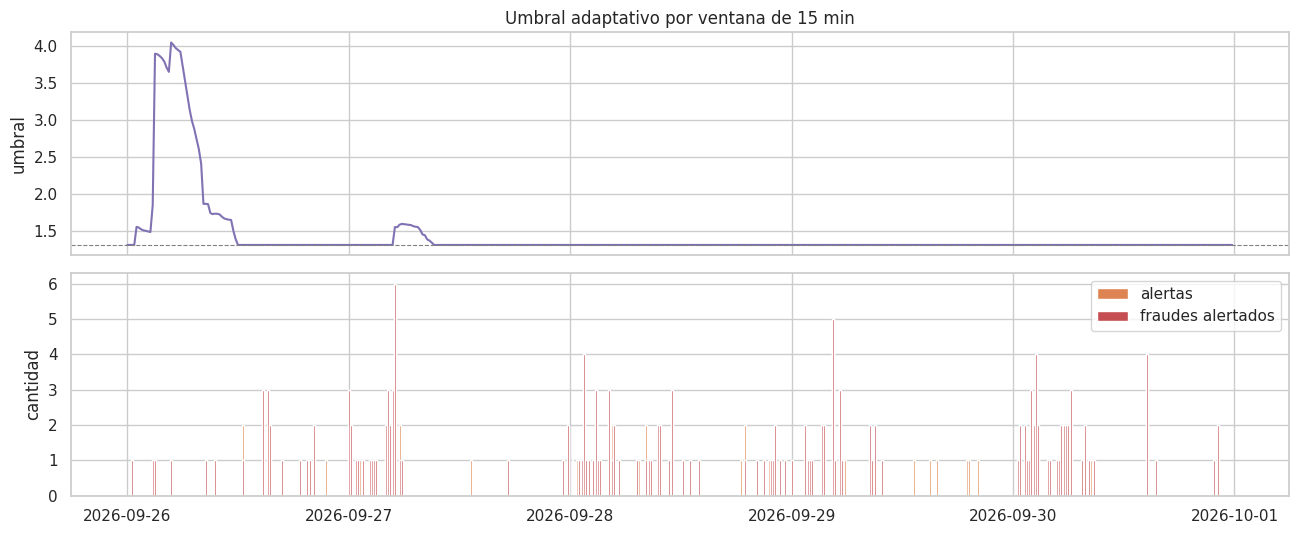

In [27]:
stream = test.sort_values('fecha_hora').reset_index(drop=True)
stream['ventana'] = stream.fecha_hora.dt.floor('15min')            # ventana tumbling de 15 minutos
CAPACIDAD = 25                                                      # alertas máximas que el equipo revisa por ventana
umbral_base = mejor_umbral(y_va, score_hibrido(X_va))             # mismo umbral usado en la tabla del Paso 20
historial, registros = [], []
print(f'Umbral base del híbrido (calibrado en validación): {umbral_base:.3f}')

for v, lote in stream.groupby('ventana'):
    t = time.perf_counter()
    s = score_hibrido(preprocesador.transform(lote[FEATS]))
    lat_ms = (time.perf_counter() - t)*1000
    historial.extend(s); historial = historial[-20_000:]            # ventana deslizante de scores recientes
    umbral = max(umbral_base, np.percentile(historial, 99.0))       # solo sube si aumentan los scores altos
    alertas = s >= umbral
    if alertas.sum() > CAPACIDAD:                                   # protección contra alert fatigue
        umbral = np.sort(s)[-CAPACIDAD]; alertas = s >= umbral
    registros.append([v, len(lote), lat_ms, umbral, alertas.sum(), lote.es_fraude.values[alertas].sum(), lote.es_fraude.sum()])

sim = pd.DataFrame(registros, columns=['ventana','tx','latencia_ms','umbral','alertas','fraudes_alertados','fraudes_reales'])
print(f'Ventanas procesadas: {len(sim)} | tx por ventana (media): {sim.tx.mean():.0f} | latencia media: {sim.latencia_ms.mean():.1f} ms | p99: {sim.latencia_ms.quantile(.99):.1f} ms')
print(f'Recall en streaming: {sim.fraudes_alertados.sum()/sim.fraudes_reales.sum():.3f} | Precision: {sim.fraudes_alertados.sum()/sim.alertas.sum():.3f} | alertas totales: {sim.alertas.sum()}')

fig, ax = plt.subplots(2, 1, figsize=(13,5.5), sharex=True)
ax[0].plot(sim.ventana, sim.umbral, color='#8172B3'); ax[0].axhline(umbral_base, ls='--', color='gray', lw=.8)
ax[0].set_ylabel('umbral'); ax[0].set_title('Umbral adaptativo por ventana de 15 min')
ax[1].bar(sim.ventana, sim.alertas, width=.009, color='#DD8452', label='alertas')
ax[1].bar(sim.ventana, sim.fraudes_alertados, width=.009, color='#C44E52', label='fraudes alertados')
ax[1].legend(); ax[1].set_ylabel('cantidad')
plt.tight_layout(); plt.savefig(FIG/'10_simulacion_streaming.png', dpi=150); plt.show()
sim.to_csv(RES/'simulacion_streaming.csv', index=False)

**Explicación del código:**
- Reproduce los 5 días de prueba como si llegaran en tiempo real, agrupándolos en ventanas tumbling de 15 minutos.
- En cada ventana se preprocesa y se puntúa con el modelo híbrido, midiendo la latencia.
- El umbral base es exactamente el mismo que se calibró en validación para el híbrido en la tabla comparativa.
- El **umbral adaptativo** es el mayor entre ese umbral base y el percentil 99 de los últimos 20.000 scores: en operación normal manda el umbral calibrado y solo sube si de pronto aparecen muchos scores altos (una falla de datos o una campaña masiva); además, si las alertas superan la capacidad del equipo (25 por ventana) se toman solo las más graves, para evitar la fatiga de alertas.
- Se reportan recall, precision y latencia de la simulación, y se grafica la evolución del umbral y de las alertas.

## Paso 26. Tamaño de lote vs. latencia y throughput

,tamaño_lote,ms_inferencia_medido,ms_total_estimado,throughput_tx_s
0,1,12.8,16.8,59.7
1,10,10.8,14.8,676.5
2,100,14.9,18.9,5291.1
3,500,31.1,35.1,14262.2
4,1000,54.0,58.0,17234.4
5,5000,222.5,226.5,22076.8
6,10000,415.0,419.0,23868.1
7,25000,1287.8,1291.8,19353.0


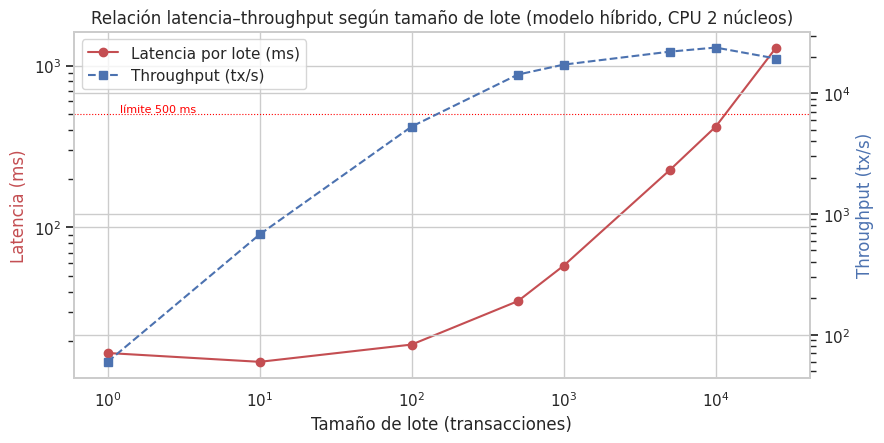

Carga media del banco: 41 tx/s | pico estimado (x5): 203 tx/s


In [28]:
TAMANOS = [1, 10, 100, 500, 1_000, 5_000, 10_000, 25_000]
OVERHEAD_KAFKA_MS = 4.0      # estimado: poll + deserialización + commit por lote (valor de referencia)
filas = []
pool = test[FEATS]
for n in TAMANOS:
    muestra = pool.sample(n, replace=n > len(pool), random_state=SEED)
    tiempos = []
    for _ in range(7 if n <= 10_000 else 3):
        t = time.perf_counter(); score_hibrido(preprocesador.transform(muestra)); tiempos.append(time.perf_counter()-t)
    ms = 1000*np.median(tiempos)
    filas.append([n, ms, ms + OVERHEAD_KAFKA_MS, n/((ms + OVERHEAD_KAFKA_MS)/1000)])
lat = pd.DataFrame(filas, columns=['tamaño_lote','ms_inferencia_medido','ms_total_estimado','throughput_tx_s'])
display(lat.round(1)); lat.to_csv(RES/'latencia_vs_batch.csv', index=False)

fig, ax1 = plt.subplots(figsize=(9,4.6)); ax2 = ax1.twinx()
ax1.plot(lat.tamaño_lote, lat.ms_total_estimado, 'o-', color='#C44E52', label='Latencia por lote (ms)')
ax2.plot(lat.tamaño_lote, lat.throughput_tx_s, 's--', color='#4C72B0', label='Throughput (tx/s)')
ax1.axhline(500, color='red', lw=.8, ls=':'); ax1.text(1.2, 520, 'límite 500 ms', color='red', fontsize=8)
ax1.set_xscale('log'); ax1.set_yscale('log'); ax2.set_yscale('log')
ax1.set_xlabel('Tamaño de lote (transacciones)'); ax1.set_ylabel('Latencia (ms)', color='#C44E52'); ax2.set_ylabel('Throughput (tx/s)', color='#4C72B0')
ax1.set_title('Relación latencia–throughput según tamaño de lote (modelo híbrido, CPU 2 núcleos)')
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax1.legend(h1+h2, l1+l2, loc='upper left')
plt.tight_layout(); plt.savefig(FIG/'11_latencia_vs_batch.png', dpi=150); plt.show()
print(f'Carga media del banco: {3_500_000/86_400:.0f} tx/s | pico estimado (x5): {5*3_500_000/86_400:.0f} tx/s')

**Explicación del código:**
- Mide el tiempo real de preprocesar y puntuar lotes de 1 a 25.000 transacciones con el modelo híbrido (mediana de varias repeticiones).
- Suma un costo fijo estimado de 4 ms por lote para consumir y confirmar mensajes en Kafka (dato de referencia, no medido).
- Calcula el throughput (transacciones por segundo) y grafica ambos ejes: lotes pequeños dan baja latencia pero poco throughput; lotes grandes al revés.
- Compara con la carga del banco: 3,5 millones de transacciones diarias equivalen a unas 41 tx/s en promedio.

# FASE 4 · Interpretación y explicabilidad

## Paso 27. Valores de Shapley por permutaciones (enfoque SHAP) – importancia global

Cálculo SHAP: 24.1 s
Error medio de aditividad: 0.174


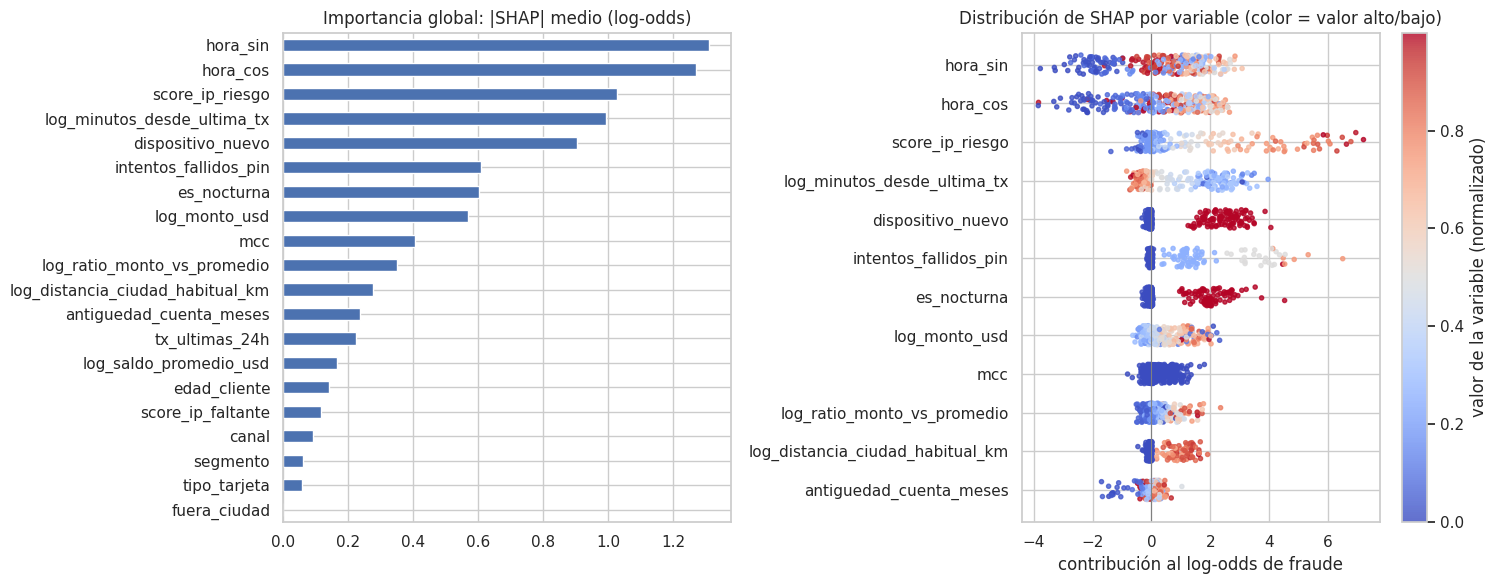

,|SHAP| medio
hora_sin,1.310
hora_cos,1.268
score_ip_riesgo,1.025
log_minutos_desde_ultima_tx,0.992
dispositivo_nuevo,0.903
intentos_fallidos_pin,0.607
es_nocturna,0.602
log_monto_usd,0.567
mcc,0.405
log_ratio_monto_vs_promedio,0.348


In [29]:
# Agrupamos las columnas one-hot para explicar en términos de la variable original
grupos = {}
for i, n in enumerate(nombres):
    base = n.split('__', 1)[1]
    for c in CAT:
        if base.startswith(c + '_'): base = c
    grupos.setdefault(base, []).append(i)
G = list(grupos); idx_grupos = [grupos[g] for g in G]

def shapley_muestreo(f, X, fondo, n_perm=40, seed=SEED):
    # Estimación de valores de Shapley por permutaciones (Štrumbelj y Kononenko, 2014), mismo concepto que SHAP
    r = np.random.default_rng(seed); n, M = len(X), len(G); phi = np.zeros((n, M))
    for i in range(n):
        filas, perms = [], []
        for _ in range(n_perm):
            z = fondo[r.integers(len(fondo))].copy(); perm = r.permutation(M); perms.append(perm)
            filas.append(z.copy())
            for g in perm:
                z[idx_grupos[g]] = X[i, idx_grupos[g]]; filas.append(z.copy())
        v = f(np.array(filas)).reshape(n_perm, M+1)
        for k, perm in enumerate(perms): phi[i, perm] += np.diff(v[k])
    return phi / n_perm

f_logodds = lambda Z: np.log(np.clip(hgb.predict_proba(Z)[:,1], 1e-6, 1-1e-6) / np.clip(hgb.predict_proba(Z)[:,0], 1e-6, 1))
fondo = X_normal[rng.choice(len(X_normal), 200, replace=False)]
sel = np.r_[rng.choice(np.flatnonzero(y_te == 1), 150, replace=False), rng.choice(np.flatnonzero(y_te == 0), 150, replace=False)]
t = time.perf_counter(); phi = shapley_muestreo(f_logodds, X_te[sel], fondo); print(f'Cálculo SHAP: {time.perf_counter()-t:.1f} s')

# Verificación de aditividad: suma de contribuciones ≈ f(x) − E[f(fondo)]
print('Error medio de aditividad:', np.abs(phi.sum(1) - (f_logodds(X_te[sel]) - f_logodds(fondo).mean())).mean().round(3))

imp = pd.Series(np.abs(phi).mean(0), index=G).sort_values()
imp.to_frame('|SHAP| medio').sort_values('|SHAP| medio', ascending=False).round(3).to_csv(RES/'importancia_shap_hgb.csv')
fig, ax = plt.subplots(1, 2, figsize=(15,6))
imp.plot.barh(ax=ax[0], color='#4C72B0'); ax[0].set_title('Importancia global: |SHAP| medio (log-odds)')
orden = imp.index[::-1][:12]
valor_original = {g: X_te[sel][:, idx_grupos[G.index(g)]].sum(1) if g in CAT else X_te[sel][:, idx_grupos[G.index(g)][0]] for g in orden}
for j, g in enumerate(orden):
    y = len(orden)-1-j + rng.uniform(-.25,.25,len(sel)); c = valor_original[g]
    sc = ax[1].scatter(phi[:, G.index(g)], y, c=(c-c.min())/(np.ptp(c)+1e-9), cmap='coolwarm', s=9, alpha=.8)
ax[1].set_yticks(range(len(orden))); ax[1].set_yticklabels(orden[::-1]); ax[1].axvline(0, color='gray', lw=.8)
ax[1].set_title('Distribución de SHAP por variable (color = valor alto/bajo)'); ax[1].set_xlabel('contribución al log-odds de fraude')
plt.colorbar(sc, ax=ax[1], label='valor de la variable (normalizado)')
plt.tight_layout(); plt.savefig(FIG/'12_shap_global_hgb.png', dpi=150); plt.show()
display(imp.sort_values(ascending=False).head(10).round(3).to_frame('|SHAP| medio'))

**Explicación del código:**
- Las columnas one-hot se agrupan (por ejemplo, todas las de `canal`) para explicar con las variables originales.
- `shapley_muestreo` estima los valores de Shapley recorriendo permutaciones aleatorias de variables y midiendo cuánto cambia la predicción al "revelar" cada una frente a un fondo de transacciones normales. Es el mismo fundamento teórico de la librería `shap`, pero **no se usa esa librería**: el cálculo está implementado aquí para que sea transparente y no dependa de paquetes externos. Si se desea comparar, puede ejecutarse `shap.TreeExplainer(hgb)` y el ranking de variables debería ser muy similar.
- Se comprueba la propiedad de aditividad: la suma de contribuciones de cada transacción reproduce su predicción menos la predicción media (el pequeño error restante se debe al muestreo de permutaciones).
- La barra muestra la importancia global y el gráfico de puntos indica la dirección: rojo = valor alto de la variable.

## Paso 28. Explicación local de una alerta concreta

Transacción TX0179822 | 2026-09-30 07:52:00 | Banca web | Electrónica | USD 955.71 | Guayaquil (habitual: Loja)
Probabilidad de fraude: 1.000


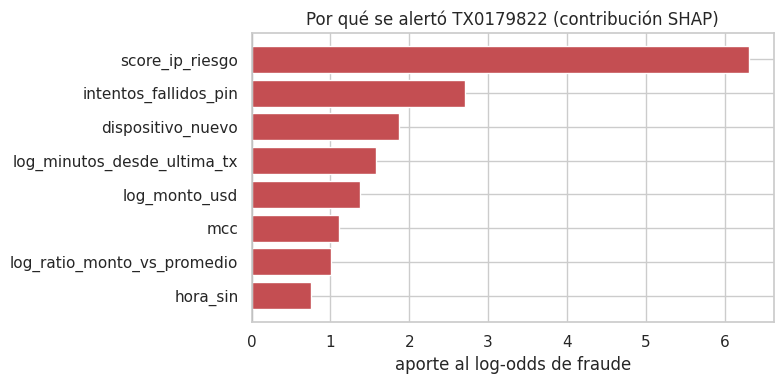

,SHAP
score_ip_riesgo,6.308
intentos_fallidos_pin,2.709
dispositivo_nuevo,1.868
log_minutos_desde_ultima_tx,1.582
log_monto_usd,1.376
mcc,1.110
log_ratio_monto_vs_promedio,1.003
hora_sin,0.756


In [30]:
prob = hgb.predict_proba(X_te[sel])[:,1]
i = int(np.argmax(np.where(y_te[sel] == 1, prob, -1)))                # fraude con mayor probabilidad
tx = test.iloc[sel[i]]
print('Transacción', tx.id_transaccion, '|', tx.fecha_hora, '|', tx.canal, '|', tx.descripcion_mcc, '|',
      f'USD {tx.monto_usd:,.2f}', '|', tx.ciudad_transaccion, f'(habitual: {tx.ciudad_habitual})')
print(f'Probabilidad de fraude: {prob[i]:.3f}')
contrib = pd.Series(phi[i], index=G).sort_values(key=abs, ascending=False).head(8)[::-1]
plt.figure(figsize=(8,4)); plt.barh(contrib.index, contrib.values, color=np.where(contrib.values > 0, '#C44E52', '#4C72B0'))
plt.axvline(0, color='gray', lw=.8); plt.title(f'Por qué se alertó {tx.id_transaccion} (contribución SHAP)'); plt.xlabel('aporte al log-odds de fraude')
plt.tight_layout(); plt.savefig(FIG/'13_shap_local.png', dpi=150); plt.show()
display(contrib[::-1].round(3).to_frame('SHAP'))

**Explicación del código:** toma el fraude del conjunto explicado con mayor probabilidad, muestra sus datos y grafica las 8 variables que más empujaron la decisión (rojo = hacia fraude, azul = hacia normal). Este es el tipo de explicación que se adjuntaría a cada alerta para el analista y para responder al cliente.

## Paso 29. SHAP del Autoencoder (modelo no supervisado del híbrido)

,HGB supervisado,Autoencoder
variable (ranking),,
hora_sin,1,6
hora_cos,2,5
score_ip_riesgo,3,1
log_minutos_desde_ultima_tx,4,7
dispositivo_nuevo,5,12
intentos_fallidos_pin,6,2
es_nocturna,7,13
log_monto_usd,8,9
mcc,9,19


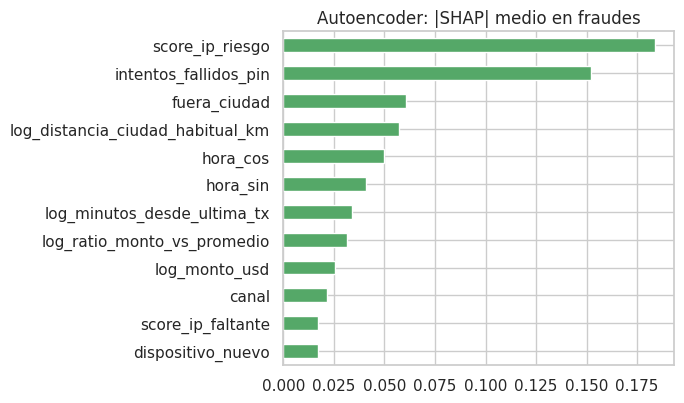

In [31]:
phi_if = shapley_muestreo(error_reconstruccion, X_te[sel[:150]], fondo, n_perm=30)
imp_if = pd.Series(np.abs(phi_if).mean(0), index=G).sort_values(ascending=False)
comp = pd.DataFrame({'HGB supervisado': imp.sort_values(ascending=False).rank(ascending=False),
                     'Autoencoder': imp_if.rank(ascending=False)}).sort_values('HGB supervisado').head(10).astype(int)
display(comp.rename_axis('variable (ranking)'))
imp_if.head(12)[::-1].plot.barh(figsize=(7,4.2), color='#55A868', title='Autoencoder: |SHAP| medio en fraudes')
plt.tight_layout(); plt.savefig(FIG/'14_shap_autoencoder.png', dpi=150); plt.show()

**Explicación del código:** aplica la misma explicación al error de reconstrucción del autoencoder sobre los 150 fraudes de la muestra y compara el ranking de variables con el del modelo supervisado, para ver si ambos "miran" lo mismo o si el no supervisado se apoya en otras señales.